STUDENT PERFORMANCE ANALYZER
Student  Maths  Science  English  Average Performance
  Aisha     85       88       90    87.67   Excellent
   Sara     72       80       85    79.00        Good
   Zoya     90       85       88    87.67   Excellent
 Mariam     65       70       75    70.00        Good
    Ali     78       75       80    77.67        Good
   Omar     88       90       82    86.67   Excellent
   Noor     92       89       94    91.67   Excellent
   Hana     70       76       84    76.67        Good

TOP-PERFORMING STUDENT
Name: Noor
Average: 91.67

AVERAGE MARKS BY SUBJECT
Maths      80.00
Science    81.62
English    84.75
dtype: float64


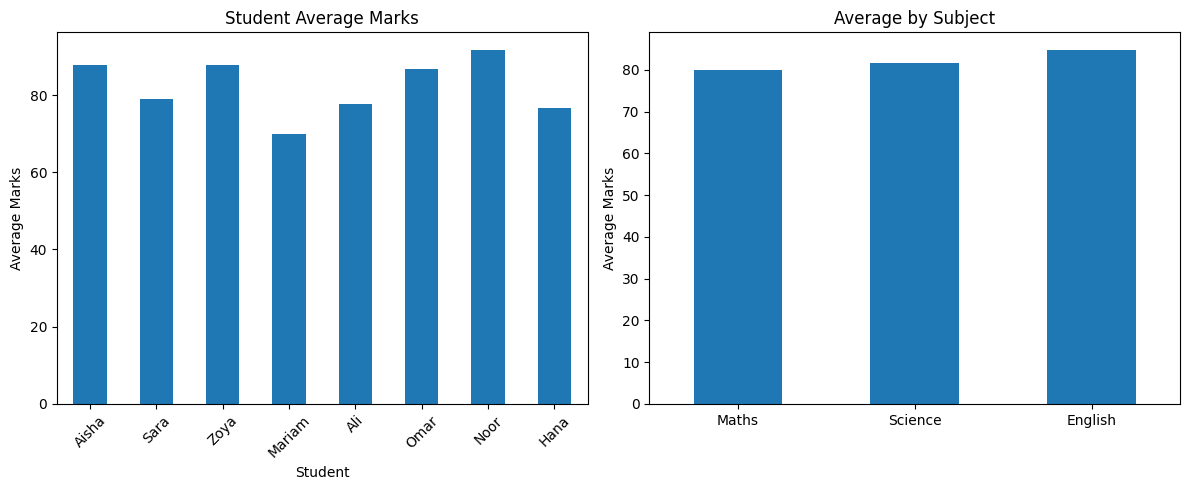

In [27]:

import pandas as pd
import matplotlib.pyplot as plt

# 1. Sample student data
data = {
    "Student": [
        "Aisha", "Sara", "Zoya", "Mariam",
        "Ali", "Omar", "Noor", "Hana"
    ],
    "Maths": [85, 72, 90, 65, 78, 88, 92, 70],
    "Science": [88, 80, 85, 70, 75, 90, 89, 76],
    "English": [90, 85, 88, 75, 80, 82, 94, 84]
}

df = pd.DataFrame(data)

# 2. Calculate each student's average
subjects = ["Maths", "Science", "English"]
df["Average"] = df[subjects].mean(axis=1).round(2)

# 3. Assign performance categories
def get_performance(average):
    if average >= 85:
        return "Excellent"
    elif average >= 70:
        return "Good"
    elif average >= 50:
        return "Average"
    else:
        return "Needs Improvement"

df["Performance"] = df["Average"].apply(get_performance)

# 4. Display the results
print("STUDENT PERFORMANCE ANALYZER")
print("=" * 35)
print(df.to_string(index=False))

# 5. Find the top-performing student
top_student = df.loc[df["Average"].idxmax()]

print("\nTOP-PERFORMING STUDENT")
print("Name:", top_student["Student"])
print("Average:", top_student["Average"])

# 6. Calculate subject averages
subject_averages = df[subjects].mean().round(2)

print("\nAVERAGE MARKS BY SUBJECT")
print(subject_averages)

# 7. Create charts
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

df.plot(
    x="Student",
    y="Average",
    kind="bar",
    ax=axes[0],
    legend=False,
    title="Student Average Marks"
)
axes[0].set_ylabel("Average Marks")
axes[0].tick_params(axis="x", rotation=45)

subject_averages.plot(
    kind="bar",
    ax=axes[1],
    title="Average by Subject"
)
axes[1].set_ylabel("Average Marks")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


In [28]:

# PROFESSIONAL SUMMARY

class_average = round(df["Average"].mean(), 2)
highest_average = round(df["Average"].max(), 2)
lowest_average = round(df["Average"].min(), 2)

print("📊 CLASS SUMMARY")
print("-" * 30)
print(f"Total students: {len(df)}")
print(f"Class average: {class_average}%")
print(f"Highest average: {highest_average}%")
print(f"Lowest average: {lowest_average}%")

print("\n📚 PERFORMANCE DISTRIBUTION")
print(df["Performance"].value_counts())

print("\n📖 STRONGEST SUBJECT")
print(subject_averages.idxmax())

print("\n📖 SUBJECT NEEDING MOST ATTENTION")
print(subject_averages.idxmin())



📊 CLASS SUMMARY
------------------------------
Total students: 8
Class average: 82.13%
Highest average: 91.67%
Lowest average: 70.0%

📚 PERFORMANCE DISTRIBUTION
Performance
Excellent    4
Good         4
Name: count, dtype: int64

📖 STRONGEST SUBJECT
English

📖 SUBJECT NEEDING MOST ATTENTION
Maths


In [29]:

from google.colab import files
import pandas as pd

print("Upload a CSV file containing student marks.")
uploaded = files.upload()

if uploaded:
    filename = next(iter(uploaded))
    custom_df = pd.read_csv(filename)

    print("\nUploaded data preview:")
    display(custom_df.head())

    print("\nColumn names:")
    print(custom_df.columns.tolist())


Upload a CSV file containing student marks.


KeyboardInterrupt: 

In [ ]:
print("My project is working!")


In [ ]:

# Analyze the uploaded student data

# Check that the required columns exist
required_columns = ["Student", "Maths", "Science", "English"]

if all(column in custom_df.columns for column in required_columns):
    df = custom_df.copy()

    subjects = ["Maths", "Science", "English"]
    df[subjects] = df[subjects].apply(
        pd.to_numeric, errors="raise"
    )

    if df[subjects].isna().any().any():
        raise ValueError("Some marks are missing.")

    if not df[subjects].apply(
        lambda column: column.between(0, 100).all()
    ).all():
        raise ValueError("Marks must be between 0 and 100.")

    df["Average"] = df[subjects].mean(axis=1).round(2)

    def get_performance(average):
        if average >= 85:
            return "Excellent"
        elif average >= 70:
            return "Good"
        elif average >= 50:
            return "Average"
        return "Needs Improvement"

    df["Performance"] = df["Average"].apply(get_performance)

    print("UPDATED STUDENT PERFORMANCE REPORT")
    display(df)

    print("Class average:", round(df["Average"].mean(), 2))
    print("Top student:",
          df.loc[df["Average"].idxmax(), "Student"])
else:
    print("Please check your CSV column names.")
    print("Required columns:", required_columns)
    print("Your columns:", custom_df.columns.tolist())


In [ ]:

# Analyze the uploaded student data

# Check that the required columns exist
required_columns = ["Student", "Maths", "Science", "English"]

if all(column in custom_df.columns for column in required_columns):
    df = custom_df.copy()

    subjects = ["Maths", "Science", "English"]
    df[subjects] = df[subjects].apply(
        pd.to_numeric, errors="raise"
    )

    if df[subjects].isna().any().any():
        raise ValueError("Some marks are missing.")

    if not df[subjects].apply(
        lambda column: column.between(0, 100).all()
    ).all():
        raise ValueError("Marks must be between 0 and 100.")

    df["Average"] = df[subjects].mean(axis=1).round(2)

    def get_performance(average):
        if average >= 85:
            return "Excellent"
        elif average >= 70:
            return "Good"
        elif average >= 50:
            return "Average"
        return "Needs Improvement"

    df["Performance"] = df["Average"].apply(get_performance)

    print("UPDATED STUDENT PERFORMANCE REPORT")
    display(df)

    print("Class average:", round(df["Average"].mean(), 2))
    print("Top student:",
          df.loc[df["Average"].idxmax(), "Student"])
else:
    print("Please check your CSV column names.")
    print("Required columns:", required_columns)
    print("Your columns:", custom_df.columns.tolist())


In [ ]:

import matplotlib.pyplot as plt

subjects = ["Maths", "Science", "English"]

subject_averages = df[subjects].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Student average chart
axes[0].bar(df["Student"], df["Average"])
axes[0].set_title("Student Performance")
axes[0].set_ylabel("Average Marks")
axes[0].tick_params(axis="x", rotation=45)
axes[0].set_ylim(0, 100)

# Subject average chart
axes[1].bar(subject_averages.index, subject_averages.values)
axes[1].set_title("Subject-wise Performance")
axes[1].set_ylabel("Average Marks")
axes[1].set_ylim(0, 100)

plt.tight_layout()
plt.show()

